#Динамика и кинематика манипулятора М20П

Таблица Денавита-Хартенберга для манипулятора М20П

| Звено | <font size="3">$\theta_i$ | <font size="3">$d_i$ | <font size="3">$a_i$ | <font size="3">$\alpha_i$ |
| :---: | :---: | :---: | :---: | :---: |
| 1 | <font size="3">$q_1$ | <font size="3">$d_0 + d_1$ | <font size="3">$0$ | <font size="3">$0^\circ$ |
| 2 | <font size="3">$0$   | <font size="3">$d_2$ | <font size="3">$a_2$ | <font size="3">$90^\circ$ |
| 3 | <font size="3">$0$   | <font size="3">$d_3$ | <font size="3">$0$ | <font size="3">$0^\circ$ |
| 4 | <font size="3">$q_4$ | <font size="3">$0$ | <font size="3">$0$ | <font size="3">$-90^\circ$ |
| 5 | <font size="3">$q_5$ | <font size="3">$0$ | <font size="3">$0$ | <font size="3">$90^\circ$ |
| 6 | <font size="3">$q_6$ | <font size="3">$d_G$ | <font size="3">$0$ | <font size="3">$0^\circ$ |

### Определение параметров манипулятора

| <font size="4">Параметр | <font size="4">Описание |
| :--- | :--- |
| <font size="4">$d_0, d_1$ | <font size="4">Константы, составляющие высоту основания манипулятора |
| <font size="4">$a_2$ | <font size="4">Константа, составляющая вынос плеча |
| <font size="4">$d_G$ | <font size="4">Константа, составляющая длину инструмента |
| <font size="4">$q_1$ | <font size="4">Угол поворота основания |
| <font size="4">$d_2$ | <font size="4">Выдвижение первого линейного привода |
| <font size="4">$d_3$ | <font size="4">Выдвижение второго линейного привода |
| <font size="4">$q_4, q_5, q_6$ | <font size="4">Параметры вращения кисти |

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from IPython.display import display, Math
import sympy as sp

from matplotlib.animation import FuncAnimation

import sympy as sp
import matplotlib.pyplot as plt
import time

In [ ]:
# "Библиотека" для различных операций для манипуляторов
class RMath:

    # Матрица вращения вокруг оси X
    @staticmethod
    def rx(theta):
        c, s = np.cos(theta), np.sin(theta)
        return np.array([[1, 0,  0, 0],
                         [0, c, -s, 0],
                         [0, s,  c, 0],
                         [0, 0,  0, 1]])

    # Матрица вращения вокруг оси Y
    @staticmethod
    def ry(theta):
        c, s = np.cos(theta), np.sin(theta)
        return np.array([[ c, 0, s, 0],
                         [ 0, 1, 0, 0],
                         [-s, 0, c, 0],
                         [ 0, 0, 0, 1]])

    # Матрица вращения вокруг оси Z
    @staticmethod
    def rz(theta):
        c, s = np.cos(theta), np.sin(theta)
        return np.array([[c, -s, 0, 0],
                         [s,  c, 0, 0],
                         [0,  0, 1, 0],
                         [0,  0, 0, 1]])

    # Матрица переноса
    @staticmethod
    def tran(x, y, z):
        T = np.eye(4)
        T[:3, 3] = [x, y, z]
        return T

    # Матрица Денавита-Хартенберга
    @staticmethod
    def dh_matrix(theta, d, a, alpha):
        return RMath.rz(theta) @ RMath.tran(0, 0, d) @ RMath.tran(a, 0, 0) @ RMath.rx(alpha)

    # Функция для извлечения углов из матрицы поворота
    @staticmethod
    def extract_zyz(R):
        if np.abs(R[2, 2]) < 1.0 - 1e-10:
            q5 = np.arccos(R[2, 2])
            q4 = np.arctan2(R[1, 2], R[0, 2])
            q6 = np.arctan2(R[2, 1], -R[2, 0])
        else:
            q5 = 0.0 if R[2, 2] > 0 else np.pi
            q4 = np.arctan2(R[1, 0], R[0, 0])
            q6 = 0.0
        return np.array([q4, q5, q6])

    @staticmethod
    def generate_ik_input(x, y, z, x_rotate=0, y_rotate=0, z_rotate=0):
      x_rotate_rad = np.deg2rad(x_rotate)
      y_rotate_rad = np.deg2rad(y_rotate)
      z_rotate_rad = np.deg2rad(z_rotate)

      R = RMath.rx(x_rotate_rad) @ RMath.ry(y_rotate_rad) @ RMath.rz(z_rotate_rad)

      T_target = np.eye(4)
      T_target[:3, :3] = R[:3, :3]
      T_target[:3, 3] = [x, y, z]

      return T_target

    # Функция для вывода Якобияна и некоторой информации о нем в консоль
    @staticmethod
    def print_jacobian(J):
        rows = []
        for row in J:
            rows.append(" & ".join(f"{v:.3f}" for v in row))
        matrix_latex = " \\\\ ".join(rows)

        display(Math(r"J = \begin{bmatrix}" + matrix_latex + r"\end{bmatrix}"))

        rank = np.linalg.matrix_rank(J, tol=1e-6)
        det = np.linalg.det(J)

        display(Math(r"\text{rank}(J) = " + str(rank)))
        display(Math(r"\det(J) = " + f"{det:.6f}"))

        if rank < 6:
            display(Math(r"\text{Сингулярность}"))
        else:
            display(Math(r"\text{Сингулярность отсутствует}"))

In [ ]:
# Класс робота М20П
class M20P:
    def __init__(self, d0=0.1, d1=0.1, a2=0.5, d_G = 0.3):
        self.d0 = d0 # Высота основания 0
        self.d1 = d1 # Высота основания 1
        self.a2 = a2 # Смещение плеча
        self.d_G = d_G # Длина инструмента

    # Прямая кинематика. Вычисление положения инструмента
    def forward_kinematics(self, q):
        T01 = RMath.dh_matrix(q[0], self.d0 + self.d1, 0, 0)
        T12 = RMath.dh_matrix(0, q[1], self.a2, np.pi/2)
        T23 = RMath.dh_matrix(0, q[2], 0, 0)

        R_wrist = RMath.dh_matrix(q[3], 0, 0, -np.pi/2) @ RMath.dh_matrix(q[4], 0, 0, np.pi/2) @ RMath.dh_matrix(q[5], self.d_G, 0, 0);

        T_total = T01 @ T12 @ T23 @ R_wrist
        return T_total

    # Обратная кинематика
    def inverse_kinematics(self, T_target):
        P_tip = T_target[:3, 3]
        R_target = T_target[:3, :3]
        P_wc = P_tip - self.d_G * R_target[:3, 2]

        x, y, z = P_wc
        R_xy = np.sqrt(x**2 + y**2)

        if R_xy < self.a2:
            return None

        q1 = np.arccos(self.a2/R_xy) + np.atan2(y, x)
        d3 = np.sqrt((x-self.a2*np.cos(q1))**2 + (y-self.a2*np.sin(q1))**2)
        d2 = z - self.d0 - self.d1

        T03 = self.forward_kinematics([q1, d2, d3, 0, 0, 0])
        R03 = T03[:3, :3]

        R_wrist = R03.T @ R_target
        q4, q5, q6 = RMath.extract_zyz(R_wrist)

        return [q1, d2, d3, q4, q5, q6]

    # Вычисление якобияна
    def jacobian(self, q):
        T01 = RMath.dh_matrix(q[0], self.d0 + self.d1, 0, 0)
        T12 = RMath.dh_matrix(0, q[1], self.a2, np.pi/2)
        T23 = RMath.dh_matrix(0, q[2], 0, 0)
        T34 = RMath.dh_matrix(q[3], 0, 0, -np.pi/2)
        T45 = RMath.dh_matrix(q[4], 0, 0, np.pi/2)
        T56 = RMath.dh_matrix(q[5], self.d_G, 0, 0)

        T = [np.eye(4), T01, T01@T12, T01@T12@T23,
            T01@T12@T23@T34, T01@T12@T23@T34@T45,
            T01@T12@T23@T34@T45@T56]

        pe = T[6][:3, 3] # Позиция конца инструмента
        J = np.zeros((6, 6))
        joint_types = ['R', 'L', 'L', 'R', 'R', 'R'] # Типы шаринров, где R-вращательный, L-линейный
        for i in range(6):
            z = T[i][:3, 2]
            p = T[i][:3, 3]
            if joint_types[i] == 'R':
                J[:3, i] = np.cross(z, pe - p)
                J[3:, i] = z
            else:
                J[:3, i] = z
                J[3:, i] = np.zeros(3)
        return J

    # Вычисление якобияна численным методом
    def numerical_jacobian(self, q, eps=1e-7):
        J = np.zeros((6, 6))

        T0 = self.forward_kinematics(q)
        p0 = T0[:3, 3]
        R0 = T0[:3, :3]

        for i in range(6):
            q_plus = q.copy()
            q_plus[i] += eps

            T_plus = self.forward_kinematics(q_plus)
            p_plus = T_plus[:3, 3]
            R_plus = T_plus[:3, :3]

            J[:3, i] = (p_plus - p0) / eps

            dR = (R_plus - R0) / eps
            S = dR @ R0.T
            J[3, i] = S[2, 1]
            J[4, i] = S[0, 2]
            J[5, i] = S[1, 0]
        return J

    # Симуляция прямой дифференциальной кинематики
    def simulate_forward_differential_kimenatics(self, q0, q_speeds, dt, steps):
        q = np.array(q0, dtype=float)
        q_speeds = np.array(q_speeds, dtype=float)
        q_records = [q.copy()]
        endeffector_pos_records = [self.forward_kinematics(q)[:3, 3].copy()]
        for _ in range(steps):
            q += q_speeds * dt
            q_records.append(q.copy())
            endeffector_pos_records.append(self.forward_kinematics(q)[:3,3].copy())
        return np.array(q_records), np.array(endeffector_pos_records)

    # Симуляция обратной дифференциальной кинематики
    def simulate_inverse_differential_kimenatics(self, q0, x_speeds, dt, steps, inversion_method="pseudoinverse"):
        q = np.array(q0, dtype=float)
        x_speeds = np.array(x_speeds, dtype=float)
        q_records = [q.copy()]
        endeffector_pos_records = [self.forward_kinematics(q)[:3, 3].copy()]

        for _ in range(steps):
            J = self.jacobian(q)
            n = len(q)

            if inversion_method == "pseudoinverse":
                J_inv = np.linalg.pinv(J)
                q_dot = J_inv @ x_speeds
            elif inversion_method == 'nullspace_manipulativity_damping':
                JJt = J @ J.T

                lambda_damping = 1e-3
                J_inv = J.T @ np.linalg.inv(JJt + lambda_damping * lambda_damping * np.eye(J.shape[0]))
                qdot_primary = J_inv @ x_speeds

                def manipulability(q):
                    J = self.jacobian(q)
                    return np.sqrt(max(np.linalg.det(J @ J.T), 0.0))

                def grad_manip(q, eps=1e-6):
                    g = np.zeros_like(q)
                    w0 = manipulability(q)
                    for i in range(len(q)):
                        dq = np.zeros_like(q)
                        dq[i] = eps
                        g[i] = (manipulability(q + dq) - w0) / eps
                    return g
                grad_w = grad_manip(q)
                P = np.eye(len(q)) - J_inv @ J
                k0 = 5.0
                q_dot = qdot_primary + P @ (k0 * grad_w)
            q = q + q_dot * dt
            q_records.append(q.copy())
            endeffector_pos_records.append(self.forward_kinematics(q)[:3,3].copy())
        return np.array(q_records), np.array(endeffector_pos_records)

    # Функция для визуализации манипулятора
    def visualize(self, q):
        T01 = RMath.dh_matrix(q[0], self.d0 + self.d1, 0, 0)
        T12_1 = T01 @ RMath.dh_matrix(0, q[1], 0, 0)
        T12_2 = T12_1 @ RMath.dh_matrix(0, 0, self.a2, np.pi/2)
        T23 = T12_2 @ RMath.dh_matrix(0, q[2], 0, 0)

        T34 = T23 @ RMath.dh_matrix(q[3], 0, 0, -np.pi/2)
        T45 = T34 @ RMath.dh_matrix(q[4], 0, 0, np.pi/2)
        T56 = T45 @ RMath.dh_matrix(q[5], self.d_G, 0, 0)

        p0 = np.array([0, 0, 0])          # Основание
        p1 = T01[:3, 3]                   # Мотор q1
        p2 = T12_1[:3, 3]                 # Линейный привод d2
        p3 = T12_2[:3, 3]                 # Плечо
        p4 = T23[:3, 3]                   # Линейный привод d3
        p_end = T56[:3, 3]                # Инструмент

        origin = p_end
        scale = 0.2
        x_axis = origin + T56[:3, 0] * scale
        y_axis = origin + T56[:3, 1] * scale
        z_axis = origin + T56[:3, 2] * scale

        points = np.array([p0, p1, p2, p3, p4, p_end])
        labels = ['Основание', 'Мотор q1', 'Линейный привод d2', 'Плечо', 'Линейный привод d3', "Инструмент"]

        fig = plt.figure(figsize=(12, 12))
        ax = fig.add_axes([0.2, 0.1, 0.6, 0.8], projection='3d', computed_zorder=False)
        ax.set_box_aspect((1, 1, 1))

        ax.plot(points[:-1,0], points[:-1,1], points[:-1,2], '-o', linewidth=4, markersize=10, color='coral', zorder=5)
        ax.plot(points[-2:, 0], points[-2:, 1], points[-2:, 2], '-o', linewidth=4, markersize=10, color='maroon', zorder=5)

        ax.quiver(origin[0], origin[1], origin[2], T56[0, 0], T56[1, 0], T56[2, 0], length=scale, color='red', linewidth=2, label='Ось X Инструмента', zorder=10)
        ax.quiver(origin[0], origin[1], origin[2], T56[0, 1], T56[1, 1], T56[2, 1], length=scale, color='green', linewidth=2, label='Ось Y Инструмента', zorder=10)
        ax.quiver(origin[0], origin[1], origin[2], T56[0, 2], T56[1, 2], T56[2, 2], length=scale, color='blue', linewidth=2, label='Ось Z Инструмента', zorder=10)

        for i, p in enumerate(points):
            text = f"{labels[i]} ({p[0]:.2f}, {p[1]:.2f}, {p[2]:.2f})"
            ax.text(p[0], p[1], p[2], text, fontsize=8, fontweight='bold', zorder=15, ha='center', va='bottom')

        ax.set_xlabel('X (м)')
        ax.set_ylabel('Y (м)')
        ax.set_zlabel('Z (м)')
        ax.set_title(f"Параметры приводов: [{round(np.rad2deg(q[0]),2)}°, {round(q[1],2)}м, {round(q[2],2)}м, {round(np.rad2deg(q[3]),2)}°, {round(np.rad2deg(q[4]),2)}°, {round(np.rad2deg(q[5]),2)}°]")

        max_range = np.array([points[:,0].max()-points[:,0].min(),
                              points[:,1].max()-points[:,1].min(),
                              points[:,2].max()-points[:,2].min()]).max() / 2.0
        max_range *= 1.3
        mid_x = (points[:,0].max()+points[:,0].min()) * 0.5
        mid_y = (points[:,1].max()+points[:,1].min()) * 0.5
        ax.set_xlim(mid_x - max_range, mid_x + max_range)
        ax.set_ylim(mid_y - max_range, mid_y + max_range)
        ax.set_zlim(0, points[:,2].max() * 1.3)

        ax.plot_trisurf([mid_x-max_range, mid_x+max_range, mid_x-max_range, mid_x+max_range],
                [mid_y-max_range, mid_y-max_range, mid_y+max_range, mid_y+max_range],
                [0, 0, 0, 0], color='white', antialiased=False, zorder=1)

        plt.legend()
        plt.show()

    # Функция для визуализации рабочей области манипулятора
    def plot_workspace(self):
        q1_range = np.linspace(0, 2*np.pi, 100)
        d2_range = np.linspace(0, 1, 10)
        d3_range = np.linspace(0, 2, 20)

        x_points, y_points, z_points = [], [], []

        for q1 in q1_range:
            for d2 in d2_range:
                for d3 in d3_range:
                    T = self.forward_kinematics([q1, d2, d3, 0, 0, 0])
                    x_points.append(T[0,3])
                    y_points.append(T[1,3])
                    z_points.append(T[2,3])

        fig = plt.figure(figsize=(10, 10))
        ax = fig.add_subplot(111, projection='3d')
        ax.scatter(x_points, y_points, z_points,c=z_points, s=50, alpha=0.1, cmap='magma')
        ax.set_title("Рабочая область")

        ax.set_zlim(self.d0+self.d1, max(z_points) * 1.3)

        plt.show()

$$
a_{eff}=\frac{dq}{dt^2 \cdot (k_b(k_b-1) + k_b \cdot k_c)}
$$

In [ ]:
class PathPlanner:
    def _trapezoidal_profile(q0, qf, v_max, a_max, T, dt=1/120):
        dq = qf - q0
        dist = abs(dq)

        t_b_max = v_max / a_max
        dist_ramp = v_max * v_max / a_max

        if dist >= dist_ramp:
            t_b = t_b_max
        else:
            t_b = np.sqrt(dist / a_max)

        k_f = int(round(T / dt))
        k_b = int(round(t_b / dt))
        k_c = max(0, k_f - 2 * k_b)

        den = dt**2 * (k_b * (k_b - 1) + k_b * k_c)
        a_eff = dq / den if den != 0 else 0.0

        q = np.zeros(k_f + 1)
        dq_arr = np.zeros(k_f + 1)
        ddq_arr = np.zeros(k_f + 1)
        q[0] = q0

        for k in range(k_f):
            if k < k_b:
                ddq = a_eff
            elif k < k_b + k_c:
                ddq = 0.0
            else:
                ddq = -a_eff

            ddq_arr[k] = ddq
            dq_arr[k+1] = dq_arr[k] + ddq * dt
            q[k+1] = q[k] + dq_arr[k] * dt

        t = np.arange(0, (k_f + 1)) * dt

        return t, q, dq_arr, ddq_arr

    def _min_time_for_joint(dq, v_max, a_max):
        dist = abs(dq)
        dist_ramp = v_max**2 / a_max
        if dist >= dist_ramp:
            return v_max / a_max + dist / v_max
        else:
            return 2 * np.sqrt(dist / a_max)

    def _synchronize_joints(q0, qf, v_max_list, a_max_list):
        times = [PathPlanner._min_time_for_joint(qf[i] - q0[i], v_max_list[i], a_max_list[i]) for i in range(len(q0))]
        T_star = max(times)
        print(f"Минимальные времена по шарнирам: {[round(t, 3) for t in times]}")
        print(f"Синхронизированное время T* = {round(T_star, 3)} с")
        return T_star

    def plan_joints_path(q0, qf, v_max_list, a_max_list, dt):
        T_star = PathPlanner._synchronize_joints(q0, qf, v_max_list, a_max_list)
        trajectories = []
        for i in range(6):
            t, q, dq, ddq = PathPlanner._trapezoidal_profile(q0[i], qf[i], v_max_list[i], a_max_list[i], T_star, dt)
            trajectories.append((t, q, dq, ddq))
        return trajectories

    @staticmethod
    def _polynomial_3_points(q0, q1, q2, t1, t2, dt=1/120):
        A = np.array([
            [t1**3,   t1**4,    t1**5,    t1**6],
            [t2**3,   t2**4,    t2**5,    t2**6],
            [3*t2**2, 4*t2**3,  5*t2**4,  6*t2**5],
            [6*t2,    12*t2**2, 20*t2**3, 30*t2**4]
        ], dtype=float)

        B = np.array([
            q1 - q0,
            q2 - q0,
            0,
            0
        ], dtype=float)

        c = np.linalg.solve(A, B)
        c3, c4, c5, c6 = c

        k_f = int(round(t2 / dt))
        t = np.linspace(0, t2, k_f + 1)

        q = q0 + c3*t**3 + c4*t**4 + c5*t**5 + c6*t**6
        dq = 3*c3*t**2 + 4*c4*t**3 + 5*c5*t**4 + 6*c6*t**5
        ddq = 6*c3*t + 12*c4*t**2 + 20*c5*t**3 + 30*c6*t**4

        return t, q, dq, ddq

    @staticmethod
    def plan_polynomial_joints_path(q0_list, q1_list, q2_list, T_total, dt=1/120):
        trajectories = []

        t1 = T_total / 2.0
        t2 = T_total

        for i in range(6):
            t, q, dq, ddq = PathPlanner._polynomial_3_points(
                q0_list[i], q1_list[i], q2_list[i], t1, t2, dt
            )
            trajectories.append((t, q, dq, ddq))

        return trajectories

    @staticmethod
    def plan_cartesian_path_jacobian(manip, q_start, p_end, T_total, dt=1/120):
        p_start = manip.forward_kinematics(q_start)[:3, 3]
        v_cartesian = np.zeros(6)
        v_cartesian[:3] = (p_end - p_start) / T_total
        steps = int(T_total / dt)

        q_records, _ = manip.simulate_inverse_differential_kimenatics(
            q_start, v_cartesian, dt, steps, inversion_method='nullspace_manipulativity_damping'
        )
        return q_records

    @staticmethod
    def plan_cartesian_path_ik(manip, q_start, p_end, steps_count, T_total, dt=1/120):
        if (steps_count < 2):
            print("[Предупреждение] Количество шагов steps_count должно быть больше 1. Значение автоматически изменено на 2")
            steps_count = 2

        T_start = manip.forward_kinematics(q_start)
        p_start = T_start[:3, 3]
        R_fixed = T_start[:3, :3]

        q_waypoints = []
        for s in range(steps_count):
            p = p_start + (p_end - p_start) * (s / (steps_count - 1))
            T_tgt = np.eye(4)
            T_tgt[:3, :3] = R_fixed
            T_tgt[:3, 3] = p
            q_ik = manip.inverse_kinematics(T_tgt)
            q_waypoints.append(np.array(q_ik) if q_ik is not None else (q_waypoints[-1] if q_waypoints else np.array(q_start)))

        steps_total = int(T_total / dt)
        steps_per_segment = steps_total // (steps_count - 1)
        q_records = []

        for i in range(len(q_waypoints) - 1):
            q_A, q_B = q_waypoints[i], q_waypoints[i+1]
            for s in range(steps_per_segment):
                q_records.append((1 - (s / steps_per_segment)) * q_A + (s / steps_per_segment) * q_B)

        q_records.append(q_waypoints[-1])
        return np.array(q_records)

In [ ]:
manipulator = M20P()

Вычисление динамической модели

In [ ]:
q1, d2, d3, q4, q5, q6 = sp.symbols('q1 d2 d3 q4 q5 q6', real=True)
dq1, dd2, dd3, dq4, dq5, dq6 = sp.symbols('dq1 dd2 dd3 dq4 dq5 dq6', real=True)

d0, d1, a2, dG = sp.symbols('d0 d1 a2 dG', positive=True)

m1, m2, m3, m4, m5, m6 = sp.symbols('m1 m2 m3 m4 m5 m6', positive=True)

q_vec  = sp.Matrix([q1, d2, d3, q4, q5, q6])
dq_vec = sp.Matrix([dq1, dd2, dd3, dq4, dq5, dq6])

g = sp.Rational(981, 100)

In [ ]:
def dh(theta, d, a, alpha):
    ct, st = sp.cos(theta), sp.sin(theta)
    ca, sa = sp.cos(alpha), sp.sin(alpha)
    return sp.Matrix([
        [ct, -st*ca,  st*sa, a*ct],
        [st,  ct*ca, -ct*sa, a*st],
        [ 0,     sa,     ca,    d],
        [ 0,      0,      0,    1],
    ])

In [ ]:
T1 = dh(q1,   d0+d1,   0,     0)
T2 = dh(0,    d2,      a2,    sp.pi/2)
T3 = dh(0,    d3,      0,     0)
T4 = dh(q4,   0,       0,    -sp.pi/2)
T5 = dh(q5,   0,       0,     sp.pi/2)
T6 = dh(q6,   dG,      0,     0)

In [ ]:
F = [
    sp.eye(4),
    T1,
    T1@T2,
    T1@T2@T3,
    T1@T2@T3@T4,
    T1@T2@T3@T4@T5,
    T1@T2@T3@T4@T5@T6,
]

In [ ]:
def com_position(i):
    p_i = F[i][:3, 3]
    z_i = F[i][:3, 2]
    x_i = F[i][:3, 0]

    offsets_z = [
        (d0+d1)/2,
        d2/2,
        d3/2,
        sp.Integer(0),
        sp.Integer(0),
        dG/2,
    ]

    offsets_x = [
        sp.Integer(0),
        a2 / 2,
        sp.Integer(0),
        sp.Integer(0),
        sp.Integer(0),
        sp.Integer(0),
    ]

    return p_i + offsets_z[i] * z_i + offsets_x[i] * x_i

masses = [m1, m2, m3, m4, m5, m6]

<h2>Вычислим полную кинетическую и потенциальную энергию</h2>

$$
\mathcal{T} = \sum_{i=1}^{n} \frac{1}{2} m_i \dot{\mathbf{q}}^T J_v^{iT} J_v^i \dot{\mathbf{q}} + \frac{1}{2} \dot{\mathbf{q}}^T J_\omega^{iT} R_i \tilde{\mathcal{I}}_i R_i^T J_\omega^i \dot{\mathbf{q}}
$$

$$
\mathcal{U} = -m \mathbf{g}_0^T \mathbf{p}_c
$$

In [ ]:
inertia_tensors = []
for i in range(1, 7):
    Ixx = sp.Symbol(f'I{i}xx', positive=True)
    Iyy = sp.Symbol(f'I{i}yy', positive=True)
    Izz = sp.Symbol(f'I{i}zz', positive=True)
    inertia_tensors.append(sp.diag(Ixx, Iyy, Izz))

T_total = sp.Integer(0)
V_total = sp.Integer(0)

joint_types = ['R', 'L', 'L', 'R', 'R', 'R']

for i in range(6):
    p_cm = com_position(i)
    Jv_i = p_cm.jacobian(q_vec)
    v_cm = Jv_i @ dq_vec

    Jw_i = sp.zeros(3, 6)
    for j in range(i + 1):
        if joint_types[j] == 'R':
            Jw_i[:, j] = F[j][:3, 2]
    omega_i = Jw_i @ dq_vec

    R_i = F[i+1][:3, :3]

    T_trans = sp.Rational(1, 2) * masses[i] * v_cm.dot(v_cm)
    T_rot = sp.Rational(1, 2) * omega_i.dot(R_i @ inertia_tensors[i] @ R_i.T @ omega_i)

    T_total += T_trans + T_rot

    V_total += masses[i] * g * p_cm[2]

T_total = sp.simplify(T_total)

$$
T = \frac{1}{2} \dot{q}^T M \dot{q} = \frac{1}{2} \sum_{i,j} M_{ij} \dot{q}_i \dot{q}_j
$$

$$
\frac{\partial T}{\partial \dot{q}_k} = \frac{1}{2} \sum_{i,j} M_{ij} \frac{\partial(\dot{q}_i \dot{q}_j)}{\partial \dot{q}_k}
$$

$$Обозначим:
\delta_{ij} = \begin{cases}
1, & \text{если } i = j \\
0, & \text{если } i \neq j
\end{cases}
$$

$$
\frac{\partial(\dot{q}_i \dot{q}_j)}{\partial \dot{q}_k} = \delta_{ik} \dot{q}_j + \delta_{jk} \dot{q}_i
$$

$$
\frac{\partial T}{\partial \dot{q}_k} = \frac{1}{2} \sum_{j} M_{kj} \dot{q}_j + \frac{1}{2} \sum_{i} M_{ik} \dot{q}_i
$$

Так как матрица $M(q)$ симметричная, можем сложить оба члена:

$$
\frac{\partial T}{\partial \dot{q}_k} = \sum_{j} M_{kj} \dot{q}_j
$$

Возьмём вторую производную:
$$
\frac{\partial^{2}T}{\partial \dot{q}_{l} \partial \dot{q}_{k}} = \sum_{j} M_{kj} \frac{\partial \dot{q}_{j}}{\partial \dot{q}_{l}} = \sum_{j} M_{kj} \delta_{jl} = M_{kl}
$$

Таким образом получаем, что $M$ - это гессиан $T$ по $\dot{q}$

In [ ]:
M = sp.hessian(T_total, dq_vec)
ops_count = sp.count_ops(M)
print(f"Количество операций в матрице M: {ops_count}")

Количество операций в матрице M: 621


In [ ]:
M_simplified = sp.simplify(M)
ops_count = sp.count_ops(M_simplified)
print(f"Количество операций в упрощённой матрице M: {ops_count}")
print("Упрощённая матрица M(q)")
display(M)

Количество операций в упрощённой матрице M: 627
Упрощённая матрица M(q)


Matrix([
[I1zz + I2yy + I3yy + I4xx*sin(q4)**2 - I4zz*sin(q4)**2 + I4zz - I5xx*sin(q4)**2*sin(q5)**2 + I5xx*sin(q4)**2 - I5yy*sin(q4)**2 + I5yy + I5zz*sin(q4)**2*sin(q5)**2 + I6xx*sin(q4)**2*sin(q5)**2*sin(q6)**2 - I6xx*sin(q4)**2*sin(q5)**2 - 2*I6xx*sin(q4)**2*sin(q6)**2 + I6xx*sin(q4)**2 + 2*I6xx*sin(q4)*sin(q6)*cos(q4)*cos(q5)*cos(q6) + I6xx*sin(q6)**2 - I6yy*sin(q4)**2*sin(q5)**2*sin(q6)**2 + 2*I6yy*sin(q4)**2*sin(q6)**2 - I6yy*sin(q4)**2 - 2*I6yy*sin(q4)*sin(q6)*cos(q4)*cos(q5)*cos(q6) - I6yy*sin(q6)**2 + I6yy + I6zz*sin(q4)**2*sin(q5)**2 + a2**2*m2/4 + a2**2*m3 + a2**2*m4 + a2**2*m5 + a2**2*m6 + a2*dG*m6*sin(q5)*cos(q4) + d3**2*m3/4 + d3**2*m4 + d3**2*m5 + d3**2*m6 + d3*dG*m6*cos(q5) - dG**2*m6*sin(q4)**2*sin(q5)**2/4 + dG**2*m6/4,                        0, -a2*m3/2 - a2*m4 - a2*m5 - a2*m6 - dG*m6*sin(q5)*cos(q4)/2, -I5xx*sin(q4)*sin(q5)*cos(q5) + I5zz*sin(q4)*sin(q5)*cos(q5) + I6xx*sin(q4)*sin(q5)*sin(q6)**2*cos(q5) - I6xx*sin(q4)*sin(q5)*cos(q5) - I6xx*sin(q5)*sin(q6)*cos(q4)*c

In [ ]:
g = sp.Matrix([sp.diff(V_total, q) for q in q_vec])
ops_count = sp.count_ops(g)
print(f"Количество операций в g: {ops_count}")
display(g)

Количество операций в g: 28


Matrix([
[                                                             0],
[981*m2/200 + 981*m3/100 + 981*m4/100 + 981*m5/100 + 981*m6/100],
[                                                             0],
[                                 981*dG*m6*sin(q5)*cos(q4)/200],
[                                 981*dG*m6*sin(q4)*cos(q5)/200],
[                                                             0]])

<h2>Матрица Кориолиса</h2>

$$
c_{ijk} = \frac{1}{2} \left( \frac{\partial m_{ij}}{\partial q_k} + \frac{\partial m_{ik}}{\partial q_j} - \frac{\partial m_{jk}}{\partial q_i} \right)
$$

$$
c_{ij}(\mathbf{q}, \dot{\mathbf{q}}) = \sum_{k=1}^{n} c_{ijk} \dot{q}_k
$$

In [ ]:
C = sp.zeros(6, 6)

for i in range(6):
    for j in range(6):
        c_ij = sp.Integer(0)
        for k in range(6):
            c_ijk = sp.Rational(1, 2) * (
                sp.diff(M_simplified[i, j], q_vec[k]) +
                sp.diff(M_simplified[i, k], q_vec[j]) -
                sp.diff(M_simplified[j, k], q_vec[i])
            )
            c_ij += c_ijk * dq_vec[k]
        C[i, j] = c_ij
ops_count = sp.count_ops(C)
print(f"Количество операций в C: {ops_count}")

Количество операций в C: 3617


In [ ]:
C_simplified = sp.simplify(C)
ops_count = sp.count_ops(C_simplified)
print(f"Количество операций в упрощённом C: {ops_count}")

Количество операций в упрощённом C: 2728


<h2>Возьмём произвольные физические характеристики</h2>

In [ ]:
I1xx, I1yy, I1zz = inertia_tensors[0][0,0], inertia_tensors[0][1,1], inertia_tensors[0][2,2]
I2xx, I2yy, I2zz = inertia_tensors[1][0,0], inertia_tensors[1][1,1], inertia_tensors[1][2,2]
I3xx, I3yy, I3zz = inertia_tensors[2][0,0], inertia_tensors[2][1,1], inertia_tensors[2][2,2]
I4xx, I4yy, I4zz = inertia_tensors[3][0,0], inertia_tensors[3][1,1], inertia_tensors[3][2,2]
I5xx, I5yy, I5zz = inertia_tensors[4][0,0], inertia_tensors[4][1,1], inertia_tensors[4][2,2]
I6xx, I6yy, I6zz = inertia_tensors[5][0,0], inertia_tensors[5][1,1], inertia_tensors[5][2,2]

robot_params = {
    m1: 5.0, m2: 4.0, m3: 3.0, m4: 2.0, m5: 1.5, m6: 0.8,
    d0: 0.1, d1: 0.1, a2: 0.5, dG: 0.3,

    I1xx: 0.1,  I1yy: 0.1,  I1zz: 0.05,
    I2xx: 0.08, I2yy: 0.08, I2zz: 0.02,
    I3xx: 0.05, I3yy: 0.05, I3zz: 0.01,
    I4xx: 0.02, I4yy: 0.02, I4zz: 0.01,
    I5xx: 0.01, I5yy: 0.01, I5zz: 0.005,
    I6xx: 0.005, I6yy: 0.005, I6zz: 0.002,
}

In [ ]:
M_numeric = M_simplified.subs(robot_params)
C_numeric = C_simplified.subs(robot_params)
G_numeric = g.subs(robot_params)
print(f"Матрица M: {sp.count_ops(M_numeric)}")
print(f"Матрица C: {sp.count_ops(C_numeric)}")
print(f"Вектор G: {sp.count_ops(G_numeric)}")

Матрица M: 119
Матрица C: 397
Вектор G: 8


In [ ]:
M_final = sp.simplify(M_numeric)
C_final = sp.simplify(C_numeric)
G_final = sp.simplify(G_numeric)

print(f"Матрица M упрощенная: {sp.count_ops(M_final)}")
print(f"Матрица C упрощенная: {sp.count_ops(C_final)}")
print(f"Вектор G упрощенный: {sp.count_ops(G_final)}")

Матрица M упрощенная: 113
Матрица C упрощенная: 368
Вектор G упрощенный: 8


# Итоговые матрицы для динамики

In [ ]:
display(M_final)
display(C_final)
display(G_final)

Matrix([
[5.05*d3**2 + 0.24*d3*cos(q5) - 0.026*sin(q4)**2*sin(q5)**2 + 0.01*sin(q4)**2 + 0.12*sin(q5)*cos(q4) + 2.298,                    0, -0.12*sin(q5)*cos(q4) - 2.9, -(0.12*d3 + 0.026*cos(q5))*sin(q4)*sin(q5), 0.12*d3*cos(q4)*cos(q5) + 0.06*sin(q5) + 0.033*cos(q4), 0.002*sin(q4)*sin(q5)],
[                                                                                                          0,                  8.3,                           0,                       0.12*sin(q5)*cos(q4),                                   0.12*sin(q4)*cos(q5),                     0],
[                                                                                -0.12*sin(q5)*cos(q4) - 2.9,                    0,                        5.05,                                          0,                                          -0.12*sin(q5),                     0],
[                                                                 -(0.12*d3 + 0.026*cos(q5))*sin(q4)*sin(q5), 0.12*sin(q5)*cos(q4),     

Matrix([
[dd3*(20.2*d3 + 0.48*cos(q5))/4 - dq4*(0.104*sin(q5)**2*cos(q4) + 0.24*sin(q5) - 0.04*cos(q4))*sin(q4)/4 - dq5*(1.92*d3*sin(q5) + 0.416*sin(q4)**2*sin(q5)*cos(q5) - 0.96*cos(q4)*cos(q5))/16, 0, dq1*(5.05*d3 + 0.12*cos(q5)), -dq1*(0.104*sin(q5)**2*cos(q4) + 0.24*sin(q5) - 0.04*cos(q4))*sin(q4)/4 - dq4*(0.48*d3 + 0.104*cos(q5))*sin(q5)*cos(q4)/4 - dq5*(0.48*d3*cos(q5) - 0.104*sin(q5)**2 + 0.118)*sin(q4)/4 + 0.001*dq6*sin(q5)*cos(q4), -dq1*(1.92*d3*sin(q5) + 0.416*sin(q4)**2*sin(q5)*cos(q5) - 0.96*cos(q4)*cos(q5))/16 - dq4*(0.48*d3*cos(q5) - 0.104*sin(q5)**2 + 0.118)*sin(q4)/4 - dq5*(0.24*d3*sin(q5)*cos(q4) - 0.12*cos(q5))/2 + 0.001*dq6*sin(q4)*cos(q5), 0.001*dq4*sin(q5)*cos(q4) + 0.001*dq5*sin(q4)*cos(q5)],
[                                                                                                                                                                                           0, 0,                            0,                                                     

Matrix([
[                     0],
[                91.233],
[                     0],
[1.1772*sin(q5)*cos(q4)],
[1.1772*sin(q4)*cos(q5)],
[                     0]])

In [ ]:
M_func = sp.lambdify([q_vec], M_final, "numpy")
C_func = sp.lambdify([q_vec, dq_vec], C_final, "numpy")
G_func = sp.lambdify([q_vec], G_final, "numpy")

In [ ]:
my_bot = M20P()

In [ ]:
from IPython.display import HTML, Video
from matplotlib.animation import FuncAnimation
import matplotlib
from tqdm.notebook import tqdm

def generateanimation(bot, q_records, step=5, cmap='magma', path='/content/robotanim.mp4', additional_text=""):
    fig = plt.figure(figsize=(10.8, 10.8), facecolor='#0f0f12')
    ax = fig.add_subplot(111, projection='3d')
    ax.set_facecolor('#0f0f12')

    frames = len(q_records) // step
    progress = tqdm(total=frames, desc="Генерация анимации")
    tool_trail = []

    colormap = plt.get_cmap(cmap)
    n_body_segments = 4
    segment_colors = [colormap(0.3 + 0.5 * i / (n_body_segments - 1))
                      for i in range(n_body_segments)]

    def update(frame):
        ax.cla()
        ax.set_facecolor('#0f0f12')
        q = q_records[frame * step]

        T01   = RMath.dh_matrix(q[0], bot.d0 + bot.d1, 0, 0)
        T12_1 = T01   @ RMath.dh_matrix(0, q[1], 0, 0)
        T12_2 = T12_1 @ RMath.dh_matrix(0, 0, bot.a2, np.pi/2)
        T23   = T12_2 @ RMath.dh_matrix(0, q[2], 0, 0)
        T34   = T23   @ RMath.dh_matrix(q[3], 0, 0, -np.pi/2)
        T45   = T34   @ RMath.dh_matrix(q[4], 0, 0,  np.pi/2)
        T56   = T45   @ RMath.dh_matrix(q[5], bot.d_G, 0, 0)

        p = [np.array([0,0,0]),T01[:3,3],T12_1[:3,3],T12_2[:3,3],T23[:3,3],T34[:3,3],T45[:3,3],T56[:3,3]]

        tool_trail.append(p[-1].copy())

        body_segments = [(p[0], p[1]), (p[1], p[2]), (p[2], p[3]), (p[3], p[4])]
        for seg, color in zip(body_segments, segment_colors):
            pts = np.array(seg)
            ax.plot(pts[:,0],pts[:,1],pts[:,2],'-',lw=8,color=color,solid_capstyle='round',solid_joinstyle='round')

        tool = np.array(p[6:])
        ax.plot(tool[:,0], tool[:,1], tool[:,2],'-', lw=6, color='#444444',solid_capstyle='round', solid_joinstyle='round')

        scale = 0.3
        ax.quiver(*p[-1], *T56[:3,0], length=scale, color='#ef5350', lw=2, arrow_length_ratio=0.25)
        ax.quiver(*p[-1], *T56[:3,1], length=scale, color='#66bb6a', lw=2, arrow_length_ratio=0.25)
        ax.quiver(*p[-1], *T56[:3,2], length=scale, color='#42a5f5', lw=2, arrow_length_ratio=0.25)

        if len(tool_trail) > 1:
            trail = np.array(tool_trail)
            ax.plot(trail[:, 0], trail[:, 1], trail[:, 2], '-',
                    lw=1.5, color='#FFFFFF', alpha=0.8, zorder=10)

        x, y, z = p[-1]
        ax.text2D(0.02, 0.95, f"Позиция инструмента: ({x:.3f}, {y:.3f}, {z:.3f})",transform=ax.transAxes, color='white',fontsize=9)
        ax.text2D(0.02, 0.98, additional_text,transform=ax.transAxes, color='white',fontsize=9)

        ax.set_xlim(-2, 2); ax.set_ylim(-2, 2); ax.set_zlim(0, 3)
        ax.set_xlabel('X', color='#666'); ax.set_ylabel('Y', color='#666')
        ax.set_zlabel('Z', color='#666')
        ax.tick_params(colors='#444')
        for pane in [ax.xaxis.pane, ax.yaxis.pane, ax.zaxis.pane]:
            pane.fill = False
            pane.set_edgecolor('#2a2a2a')
        ax.grid(True, color='#2a2a2a', linewidth=0.5)
        progress.update(1)

    anim = FuncAnimation(fig, update, frames=frames, interval=50)
    plt.close()

    writer = matplotlib.animation.FFMpegWriter(fps=120)
    anim.save(path, writer=writer, dpi=200)
    progress.close()

    return Video(path, embed=True, width=800)

<h2>Поуправляем роботом</h2>
<h3>Для примера я задал роботу обойти точки в форме звезды</h3>
<h3>Прямые будут не очень ровные из-за того что трапецеидальный профиль и не гарантирует что траектория будет прямая в картезианских координатах</h3>
<h3>Также я добавил простой PD регулятор к управлению</h3>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

star_points = [
    (0.7071, -0.7071, 0.56),
    (0.8069, -0.6073, 0.9058),
    (1.0702, -0.344,  0.9331),
    (0.8685, -0.5457, 1.1742),
    (0.9315, -0.4827, 1.5369),
    (0.7071, -0.7071, 1.34),
    (0.4827, -0.9315, 1.5369),
    (0.5457, -0.8685, 1.1742),
    (0.344,  -1.0702, 0.9331),
    (0.6073, -0.8069, 0.9058),
    (0.7071, -0.7071, 0.56),
]

q_waypoints = []
for p in star_points:
    T_target = RMath.generate_ik_input(p[0], p[1], p[2], x_rotate=0, y_rotate=90, z_rotate=0)
    q_ik = my_bot.inverse_kinematics(T_target)
    if q_ik is not None:
        q_waypoints.append(q_ik)

v_max = [1.5] * 6
a_max = [3.0] * 6
dt = 1/120.0

q_d_list, dq_d_list, ddq_d_list = [], [], []

for i in range(len(q_waypoints) - 1):
    q_start = q_waypoints[i]
    q_end = q_waypoints[i+1]

    traj = PathPlanner.plan_joints_path(q_start, q_end, v_max, a_max, dt)

    q_seg = np.array([t[1] for t in traj]).T
    dq_seg = np.array([t[2] for t in traj]).T
    ddq_seg = np.array([t[3] for t in traj]).T

    if i < len(q_waypoints) - 2:
        q_d_list.extend(q_seg[:-1])
        dq_d_list.extend(dq_seg[:-1])
        ddq_d_list.extend(ddq_seg[:-1])
    else:
        q_d_list.extend(q_seg)
        dq_d_list.extend(dq_seg)
        ddq_d_list.extend(ddq_seg)

q_d = np.array(q_d_list)
dq_d = np.array(dq_d_list)
ddq_d = np.array(ddq_d_list)

q, dq = q_waypoints[0].copy(), np.zeros(6)
q_records = [q.copy()]

Kp, Kd = np.eye(6) * 150.0, np.eye(6) * 25.0
tau_history = []

for i in range(len(q_d) - 1):
    M = M_func(q)
    C = C_func(q, dq)
    g_vec = G_func(q).flatten()

    e = q_d[i] - q
    de = dq_d[i] - dq

    tau = M @ (ddq_d[i] + Kp @ e + Kd @ de) + C @ dq + g_vec
    tau_history.append(tau)

    ddq = np.linalg.inv(M) @ (tau - C @ dq - g_vec)

    dq = dq + ddq * dt
    q = q + dq * dt
    q_records.append(q.copy())

q_records = np.array(q_records)
tau_history = np.array(tau_history)

Минимальные времена по шарнирам: [np.float64(0.445), np.float64(0.679), np.float64(0.206), np.float64(0.0), np.float64(0.445), np.float64(0.0)]
Синхронизированное время T* = 0.679 с
Минимальные времена по шарнирам: [np.float64(0.821), np.float64(0.191), np.float64(0.297), np.float64(0.0), np.float64(0.821), np.float64(0.0)]
Синхронизированное время T* = 0.821 с
Минимальные времена по шарнирам: [np.float64(0.728), np.float64(0.567), np.float64(0.306), np.float64(0.0), np.float64(0.728), np.float64(0.0)]
Синхронизированное время T* = 0.728 с
Минимальные времена по шарнирам: [np.float64(0.399), np.float64(0.695), np.float64(0.108), np.float64(0.0), np.float64(0.399), np.float64(0.0)]
Синхронизированное время T* = 0.695 с
Минимальные времена по шарнирам: [np.float64(0.707), np.float64(0.512), np.float64(0.189), np.float64(0.0), np.float64(0.707), np.float64(0.0)]
Синхронизированное время T* = 0.707 с
Минимальные времена по шарнирам: [np.float64(0.546), np.float64(0.512), np.float64(0.465),

Графики сил и моментов

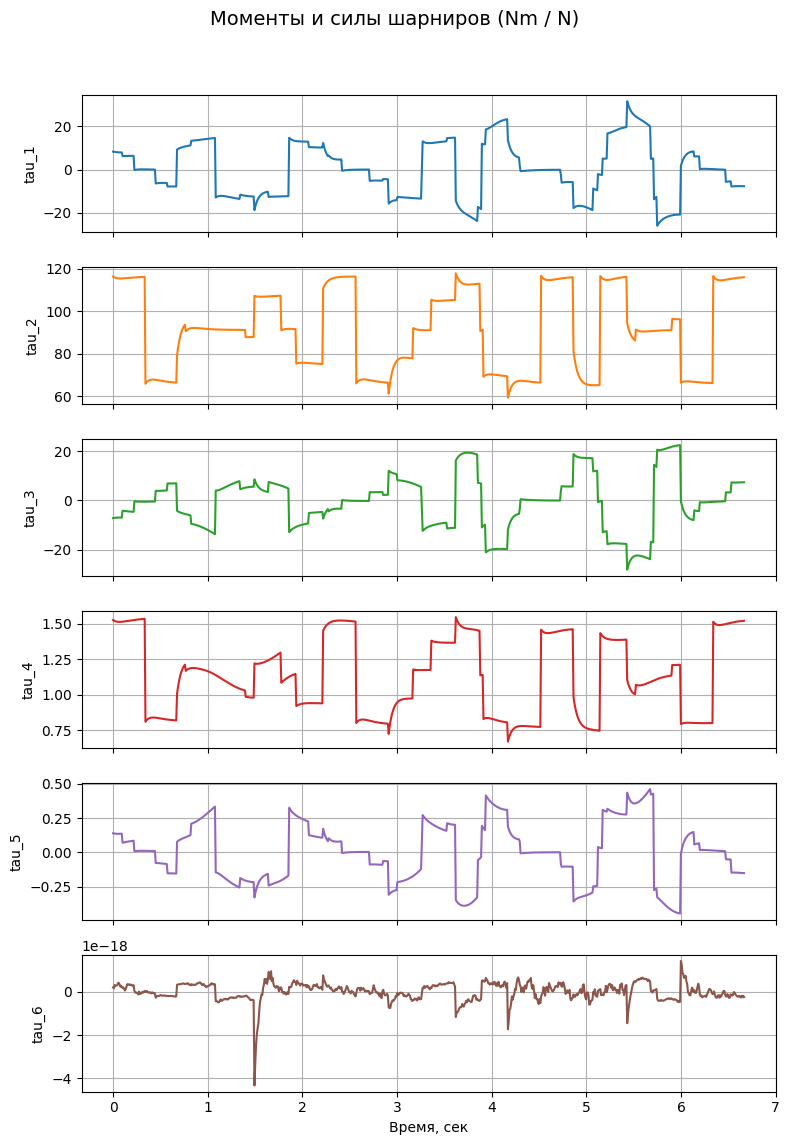

In [ ]:
time_arr = np.linspace(0, len(tau_history)*dt, len(tau_history))
fig, axs = plt.subplots(6, 1, figsize=(8, 12), sharex=True)
fig.suptitle('Моменты и силы шарниров (Nm / N)', fontsize=14)

for i in range(6):
    axs[i].plot(time_arr, tau_history[:, i], color=f'C{i}', lw=1.5)
    axs[i].set_ylabel(f'tau_{i+1}')
    axs[i].grid(True)

plt.xlabel('Время, сек')
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

Анимация

In [ ]:
generateanimation(
    my_bot,
    q_records,
    step=3,
    path='star_drawing_dynamic.mp4',
)

Генерация анимации:   0%|          | 0/267 [00:00<?, ?it/s]